In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [12]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
x = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target

x.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
#Evaluate the model

from sklearn.metrics import mean_squared_error

y_pred =model.predict(x_test_scaled)

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error : {mse: .2f}")

Mean Squared Error :  0.56


In [20]:
model.score(x_test_scaled, y_test)

0.5757877060324508

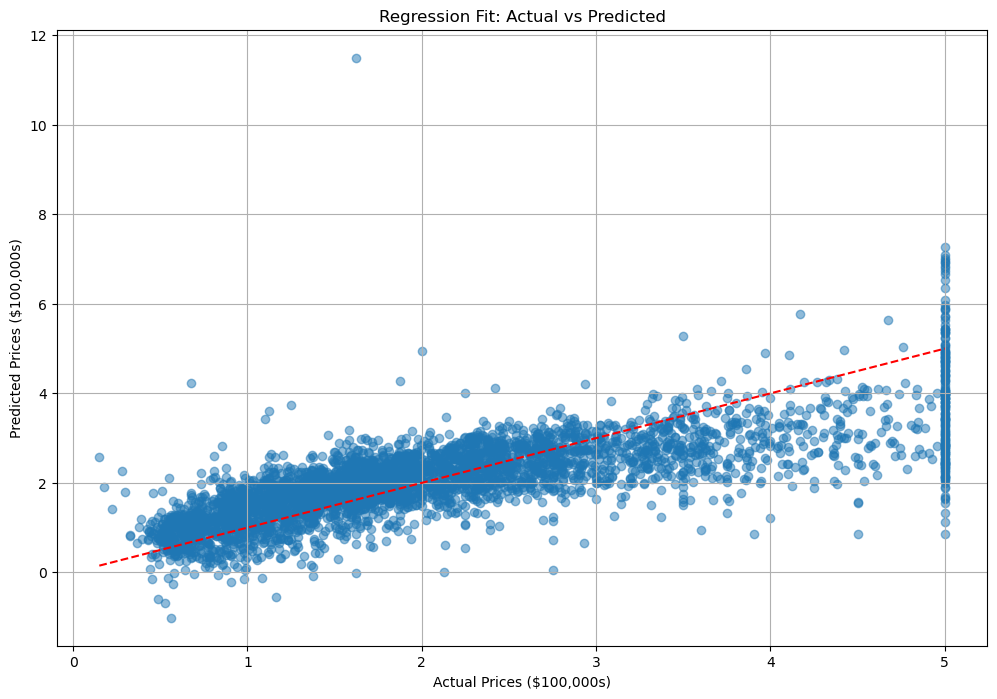

In [21]:
# Visualize: Plot Actual vs Predicted (Regression Fit)

import matplotlib.pyplot as plt 

# import seaborn as sns 
plt.figure(figsize=(12, 8)) 
plt.scatter(x=y_test, y=y_pred, alpha=.5) 
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
plt.xlabel("Actual Prices ($100,000s)") 
plt.ylabel("Predicted Prices ($100,000s)") 
plt.title("Regression Fit: Actual vs Predicted") 
plt.grid(True) 
plt.show()

In [22]:
#Using the first model, result should be the same

def predict_house_price2(MedInc, HouseAge, AveRooms, AveBedrms,  Population, AveOccup, Latitude, Longitude): 
    
 # Prepare input as a 2D array (one row, 8 features)  
    sample = [[MedInc, HouseAge, AveRooms, AveBedrms, 
     Population, AveOccup, Latitude, Longitude]]  
    sample = scaler.transform(sample) 
    predicted_price = model.predict(sample)[0]
    bla = model.predict(sample)
    return f"Estimated House Price: ${predicted_price * 100000:,.2f}" 